# Fake News Detection Using Natural Language Processing and Machine Learning

## 1. Introduction

Fake news refers to false or misleading information presented as
genuine news. With the increasing use of digital media, identifying
misleading news articles has become an important challenge.

This project develops an NLP-based Fake News Detection system
using the WELFake dataset.

The system uses text preprocessing, TF-IDF feature extraction,
and machine learning classification algorithms to classify
news articles into two categories:

- Fake News (0)
- Real News (1)

### Objectives
1. Understand and analyse the WELFake dataset.
2. Perform text preprocessing and normalization.
3. Convert textual data into numerical features using TF-IDF.
4. Train multiple machine learning models.
5. Compare models using standard evaluation metrics.
6. Analyse incorrect predictions and test new news articles.

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn nltk joblib

  Using cached defusedxml-0.7.1-py2.py3-none-any.whl.metadata (32 kB)
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ------ --------------------------------- 0.3/1.7 MB ? eta -:--:--
   ---------------------------------------- 1.7/1.7 MB 9.4 MB/s  0:00:00
Using cached defusedxml-0.7.1-py2.py3-none-any.whl (25 kB)

   ---------------------------------------- 0/2 [defusedxml]
   -------------------- ------------------- 1/2 [nltk]
   -------------------- ------------------- 1/2 [nltk]
   -------------------- ------------------- 1/2 [nltk]
   -------------------- ------------------- 1/2 [nltk]
   -------------------- ------------------- 1/2 [nltk]
   -------------------- ------------------- 1/2 [nltk]
   -------------------- ------------------- 1/2 [nltk]
   -------------------- ------------------- 1/2 [nltk]
   -------------------- ------------------- 1/2 [nltk]
   -------------------- ------------------- 1/2 [nltk]
   -------------------- ------------------- 1/2 


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
import time
import warnings

warnings.filterwarnings("ignore")

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    RocCurveDisplay
)


import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("NLTK resources downloaded successfully!")

[nltk_data] Downloading package stopwords to C:\Users\Tejas
[nltk_data]     Divekar\AppData\Roaming\nltk_data...


NLTK resources downloaded successfully!


[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package wordnet to C:\Users\Tejas
[nltk_data]     Divekar\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to C:\Users\Tejas
[nltk_data]     Divekar\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [4]:
DATA_PATH = "WELFake_Dataset.csv"

# Check whether the dataset exists
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}. "
        "Please check the file location and filename."
    )

# Load dataset
try:
    df = pd.read_csv(DATA_PATH)
except UnicodeDecodeError:
    df = pd.read_csv(DATA_PATH, encoding="latin-1")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (72134, 4)


,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


In [6]:
print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Description:")
display(df.describe(include="all"))



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72134 entries, 0 to 72133
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  72134 non-null  int64 
 1   title       71576 non-null  object
 2   text        72095 non-null  object
 3   label       72134 non-null  int64 
dtypes: int64(2), object(2)
memory usage: 2.2+ MB

Column Names:
['Unnamed: 0', 'title', 'text', 'label']

Dataset Description:


,Unnamed: 0,title,text,label
count,72134.000000,71576,72095,72134.000000
unique,NaN,62347,62718,NaN
top,NaN,Factbox: Trump fills top jobs for his administ...,,NaN
freq,NaN,14,738,NaN
mean,36066.500000,NaN,NaN,0.514404
std,20823.436496,NaN,NaN,0.499796
min,0.000000,NaN,NaN,0.000000
25%,18033.250000,NaN,NaN,0.000000
50%,36066.500000,NaN,NaN,1.000000
75%,54099.750000,NaN,NaN,1.000000


In [7]:
# Standardize column names
df.columns = [
    str(col).strip().lower().replace(" ", "_")
    for col in df.columns
]

print("Updated columns:", df.columns.tolist())

# Handle possible ID column names
id_columns = [
    col for col in df.columns
    if col in ["unnamed:_0", "unnamed:0", "serialnumber",
               "serial_number", "id"]
]

df.drop(columns=id_columns, inplace=True, errors="ignore")

# Verify required columns
required_columns = ["title", "text", "label"]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

print("Required columns verified!")

Updated columns: ['unnamed:_0', 'title', 'text', 'label']
Required columns verified!


In [8]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nMissing value percentage:")
print((df.isnull().mean() * 100).round(2))

Missing values in each column:
title    558
text      39
label      0
dtype: int64

Missing value percentage:
title    0.77
text     0.05
label    0.00
dtype: float64


In [9]:
# Remove records without a valid label
df = df.dropna(subset=["label"]).copy()

# Convert labels to numeric
df["label"] = pd.to_numeric(df["label"], errors="coerce")

df = df.dropna(subset=["label"]).copy()

# Keep only valid binary labels
df = df[df["label"].isin([0, 1])].copy()
df["label"] = df["label"].astype(int)

# Fill missing title and text with empty strings
df["title"] = df["title"].fillna("").astype(str)
df["text"] = df["text"].fillna("").astype(str)

# Remove rows where both title and text are empty
df = df[
    (df["title"].str.strip() != "") |
    (df["text"].str.strip() != "")
].copy()

df.reset_index(drop=True, inplace=True)

print("Shape after handling missing values:", df.shape)
print("Remaining missing values:")
print(df.isnull().sum())

Shape after handling missing values: (72134, 3)
Remaining missing values:
title    0
text     0
label    0
dtype: int64


In [11]:
print("Number of duplicate rows:", df.duplicated().sum())

# Remove exact duplicate records
df.drop_duplicates(inplace=True)

# Remove articles with identical title and text
df.drop_duplicates(
    subset=["title", "text"],
    inplace=True
)

df.reset_index(drop=True, inplace=True)

print("Shape after duplicate removal:", df.shape)

Number of duplicate rows: 8456
Shape after duplicate removal: (63678, 3)


In [12]:
df["content"] = (
    df["title"].str.strip() + " " +
    df["text"].str.strip()
).str.strip()

# Remove empty combined content
df = df[df["content"] != ""].copy()

print("Combined content created successfully!")

display(df[["title", "text", "content", "label"]].head())

Combined content created successfully!


,title,text,content,label
0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,1
1,,Did they post their votes for Hillary already?,Did they post their votes for Hillary already?,1
2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,1
3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,"Bobby Jindal, raised Hindu, uses story of Chri...",0
4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",SATAN 2: Russia unvelis an image of its terrif...,1


Label Distribution:
label
0    34791
1    28887
Name: count, dtype: int64

Label Meaning:
0 = Fake News
1 = Real News


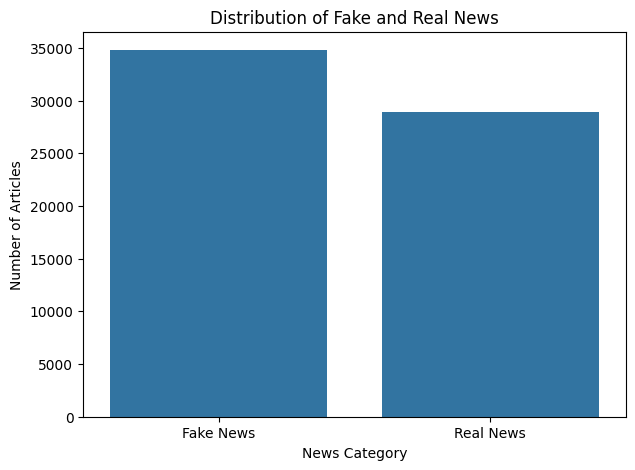

In [13]:
print("Label Distribution:")
print(df["label"].value_counts())

print("\nLabel Meaning:")
print("0 = Fake News")
print("1 = Real News")

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="label"
)

plt.title("Distribution of Fake and Real News")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.xticks([0, 1], ["Fake News", "Real News"])

plt.show()

In [15]:
df["title_word_count"] = df["title"].apply(
    lambda x: len(str(x).split())
)

df["text_word_count"] = df["text"].apply(
    lambda x: len(str(x).split())
)

df["content_word_count"] = df["content"].apply(
    lambda x: len(str(x).split())
)

print("Text Length Statistics:")
display(
    df[
        ["title_word_count", "text_word_count",
         "content_word_count"]
    ].describe()
)

Text Length Statistics:


,title_word_count,text_word_count,content_word_count
count,63678.000000,63678.000000,63678.000000
mean,11.892396,542.313578,554.205974
std,3.974641,610.412201,610.762633
min,0.000000,0.000000,1.000000
25%,9.000000,235.000000,247.000000
50%,11.000000,403.000000,414.000000
75%,14.000000,673.000000,685.000000
max,72.000000,24234.000000,24243.000000


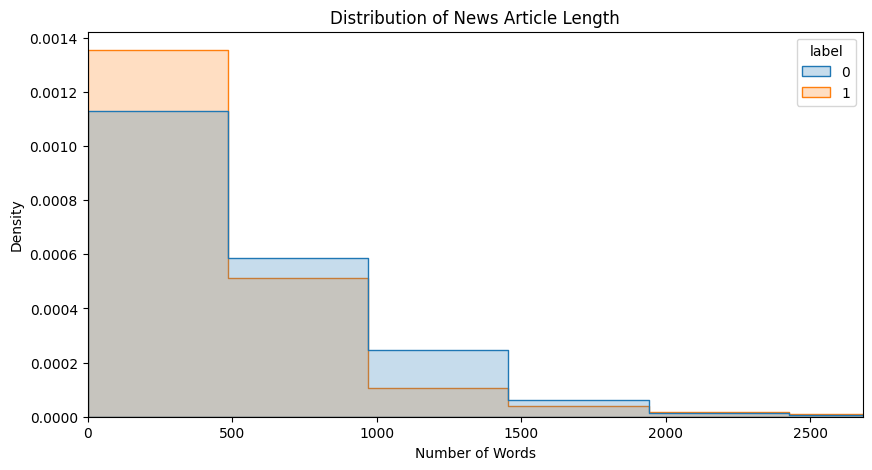

In [16]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="content_word_count",
    hue="label",
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Distribution of News Article Length")
plt.xlabel("Number of Words")
plt.ylabel("Density")
plt.xlim(0, df["content_word_count"].quantile(0.99))

plt.show()

In [17]:
print("Sample Fake News Articles:\n")

fake_samples = df[df["label"] == 0].sample(
    min(3, len(df[df["label"] == 0])),
    random_state=42
)

for index, row in fake_samples.iterrows():
    print("Title:", row["title"])
    print("Content:", row["text"][:300])
    print("-" * 80)


print("\nSample Real News Articles:\n")

real_samples = df[df["label"] == 1].sample(
    min(3, len(df[df["label"] == 1])),
    random_state=42
)

for index, row in real_samples.iterrows():
    print("Title:", row["title"])
    print("Content:", row["text"][:300])
    print("-" * 80)

Sample Fake News Articles:

Title: Zimbabwe's ruling ZANU-PF party calls for Mugabe resignation
Content: JOHANNESBURG (Reuters) - Zimbabwe s ruling ZANU-PF party called on Friday for President Robert Mugabe to resign, the main state newspaper The Herald reported, the latest sign that the aging leader s authority has collapsed after an army takeover. The newspaper said that ZANU-PF branches in all 10 pr
--------------------------------------------------------------------------------
Title: John Kerry Criticizes Russia, Saying It ‘Turned a Blind Eye’ on Syria - The New York Times
Content: BRUSSELS  —   Secretary of State John Kerry criticized Russia on Tuesday for pointedly ignoring the Syrian government’s use of chlorine gas and barrel bombs against its own citizens, and he left little hope for an early resumption of talks with Russia about a  . Speaking here before the opening of a
--------------------------------------------------------------------------------
Title: Strong economic r

## Text preprocessing

In [18]:
stop_words = set(stopwords.words("english"))

# Preserve important negation words
important_words = {"no", "not", "nor", "never"}

stop_words = stop_words - important_words

lemmatizer = WordNetLemmatizer()

print("Stopwords initialized:", len(stop_words))
print("Lemmatizer initialized successfully!")

Stopwords initialized: 195
Lemmatizer initialized successfully!


In [20]:
def preprocess_text(text):

    # Convert to string
    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(
        r"http\S+|www\.\S+",
        " ",
        text
    )

    # Remove HTML tags
    text = re.sub(
        r"<[^>]+>",
        " ",
        text
    )

    # Remove email addresses
    text = re.sub(
        r"\S+@\S+",
        " ",
        text
    )

    # Keep only alphabetic characters and spaces
    text = re.sub(
        r"[^a-z\s]",
        " ",
        text
    )

    # Normalize multiple spaces
    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    # Tokenization
    tokens = re.findall(r"\b[a-z]+\b", text)

    # Stopword removal and lemmatization
    processed_tokens = []

    for word in tokens:

        if word not in stop_words and len(word) > 1:

            lemma = lemmatizer.lemmatize(word)

            processed_tokens.append(lemma)

    return " ".join(processed_tokens)

Test preprocessing function (Code)

In [21]:
sample_text = """
BREAKING NEWS! This is a SAMPLE article.
Visit https://example.com for more information.
The government is NOT responsible for this claim.
"""

cleaned_sample = preprocess_text(sample_text)

print("Original Text:")
print(sample_text)

print("\nPreprocessed Text:")
print(cleaned_sample)

Original Text:

BREAKING NEWS! This is a SAMPLE article.
Visit https://example.com for more information.
The government is NOT responsible for this claim.


Preprocessed Text:
breaking news sample article visit information government not responsible claim


In [22]:
start_time = time.time()

df["cleaned_content"] = df["content"].apply(
    preprocess_text
)

end_time = time.time()

print("Text preprocessing completed!")
print("Time taken:", round(end_time - start_time, 2), "seconds")

display(
    df[
        ["content", "cleaned_content", "label"]
    ].head()
)

Text preprocessing completed!
Time taken: 220.77 seconds


,content,cleaned_content,label
0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,law enforcement high alert following threat co...,1
1,Did they post their votes for Hillary already?,post vote hillary already,1
2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,unbelievable obama attorney general say charlo...,1
3,"Bobby Jindal, raised Hindu, uses story of Chri...",bobby jindal raised hindu us story christian c...,0
4,SATAN 2: Russia unvelis an image of its terrif...,satan russia unvelis image terrifying new supe...,1


In [23]:
sample = df.iloc[0]

print("ORIGINAL TEXT:")
print(sample["content"][:1000])

print("\nPREPROCESSED TEXT:")
print(sample["cleaned_content"][:1000])

ORIGINAL TEXT:
LAW ENFORCEMENT ON HIGH ALERT Following Threats Against Cops And Whites On 9-11By #BlackLivesMatter And #FYF911 Terrorists [VIDEO] No comment is expected from Barack Obama Members of the #FYF911 or #FukYoFlag and #BlackLivesMatter movements called for the lynching and hanging of white people and cops. They encouraged others on a radio show Tuesday night to  turn the tide  and kill white people and cops to send a message about the killing of black people in America.One of the F***YoFlag organizers is called  Sunshine.  She has a radio blog show hosted from Texas called,  Sunshine s F***ing Opinion Radio Show. A snapshot of her #FYF911 @LOLatWhiteFear Twitter page at 9:53 p.m. shows that she was urging supporters to  Call now!! #fyf911 tonight we continue to dismantle the illusion of white Below is a SNAPSHOT Twitter Radio Call Invite   #FYF911The radio show aired at 10:00 p.m. eastern standard time.During the show, callers clearly call for  lynching  and  killing  of whit

In [24]:
df = df[
    df["cleaned_content"].str.strip() != ""
].copy()

df.reset_index(drop=True, inplace=True)

print("Final dataset shape:", df.shape)
print("Empty preprocessed records:",
      (df["cleaned_content"].str.strip() == "").sum())

Final dataset shape: (63625, 8)
Empty preprocessed records: 0


In [25]:
# Identify articles whose cleaned content has conflicting labels
label_counts = df.groupby("cleaned_content")["label"].nunique()

conflicting_articles = label_counts[label_counts > 1].index

print("Conflicting cleaned articles:", len(conflicting_articles))

# Remove ambiguous records
df = df[
    ~df["cleaned_content"].isin(conflicting_articles)
].copy()

# Remove normalized duplicates
df.drop_duplicates(
    subset=["cleaned_content"],
    keep="first",
    inplace=True
)

df.reset_index(drop=True, inplace=True)

print("Dataset shape after final duplicate handling:", df.shape)

Conflicting cleaned articles: 0
Dataset shape after final duplicate handling: (63289, 8)


In [26]:
X = df["cleaned_content"]
y = df["label"]

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Input features shape: (63289,)
Target variable shape: (63289,)

Target distribution:
label
0    34519
1    28770
Name: count, dtype: int64


In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting label distribution:")
print(y_test.value_counts(normalize=True))

Training samples: 50631
Testing samples: 12658

Training label distribution:
label
0    0.545417
1    0.454583
Name: proportion, dtype: float64

Testing label distribution:
label
0    0.545426
1    0.454574
Name: proportion, dtype: float64


In [28]:
tfidf = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    dtype=np.float32
)

print("TF-IDF Vectorizer initialized!")

TF-IDF Vectorizer initialized!


In [29]:
X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF transformation completed!")

print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

TF-IDF transformation completed!
Training matrix shape: (50631, 30000)
Testing matrix shape: (12658, 30000)


In [30]:
feature_names = tfidf.get_feature_names_out()

print("Total vocabulary size:", len(feature_names))

print("\nFirst 30 features:")
print(feature_names[:30])

# Display a sample sparse matrix
print("\nSample TF-IDF matrix:")
print(X_train_tfidf[:2, :10].toarray())

Total vocabulary size: 30000

First 30 features:
['aa' 'aaron' 'aaron klein' 'ab' 'aback' 'abadi' 'abandon' 'abandoned'
 'abandoning' 'abbas' 'abbott' 'abby' 'abc' 'abc news' 'abc week' 'abd'
 'abdel' 'abdel fattah' 'abdeslam' 'abducted' 'abduction' 'abdul'
 'abdullah' 'abe' 'abe said' 'abedin' 'abedin email' 'aber' 'abhorrent'
 'abide']

Sample TF-IDF matrix:
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


 Machine Learning model development

In [31]:
models = {
    "Naive Bayes": MultinomialNB(),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        C=1.0,
        random_state=42
    ),

    "Linear SVM": LinearSVC(
        C=1.0,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=40,
        min_samples_leaf=2,
        max_features="sqrt",
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42
    )
}

print("Models initialized:")
for model_name in models:
    print("-", model_name)

Models initialized:
- Naive Bayes
- Logistic Regression
- Linear SVM
- Random Forest


In [32]:
trained_models = {}
training_times = {}

for model_name, model in models.items():

    print(f"\nTraining {model_name}...")

    start_time = time.time()

    model.fit(X_train_tfidf, y_train)

    end_time = time.time()

    training_time = end_time - start_time

    trained_models[model_name] = model
    training_times[model_name] = training_time

    print(f"{model_name} training completed!")
    print(f"Training time: {training_time:.2f} seconds")

print("\nAll models trained successfully!")


Training Naive Bayes...
Naive Bayes training completed!
Training time: 0.27 seconds

Training Logistic Regression...
Logistic Regression training completed!
Training time: 1.24 seconds

Training Linear SVM...
Linear SVM training completed!
Training time: 2.02 seconds

Training Random Forest...
Random Forest training completed!
Training time: 14.11 seconds

All models trained successfully!


In [33]:
predictions = {}

for model_name, model in trained_models.items():

    y_pred = model.predict(X_test_tfidf)

    predictions[model_name] = y_pred

    print(f"{model_name} predictions generated!")

Naive Bayes predictions generated!
Logistic Regression predictions generated!
Linear SVM predictions generated!
Random Forest predictions generated!


In [34]:
results = []

for model_name, model in trained_models.items():

    y_pred = predictions[model_name]

    # ROC-AUC score
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test_tfidf)[:, 1]
    else:
        y_score = model.decision_function(X_test_tfidf)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_score),
        "Training Time (sec)": training_times[model_name]
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(
    results_df.round(4).style.highlight_max(
        subset=[
            "Accuracy", "Precision", "Recall",
            "F1 Score", "ROC-AUC"
        ],
        color="lightgreen"
    )
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (sec)
0,Linear SVM,0.969400,0.967300,0.965400,0.966300,0.995800,2.016000
1,Logistic Regression,0.961100,0.957700,0.956700,0.957200,0.993500,1.238700
2,Random Forest,0.936200,0.928400,0.931400,0.929900,0.984900,14.111300
3,Naive Bayes,0.883600,0.855500,0.895000,0.874800,0.952800,0.268200


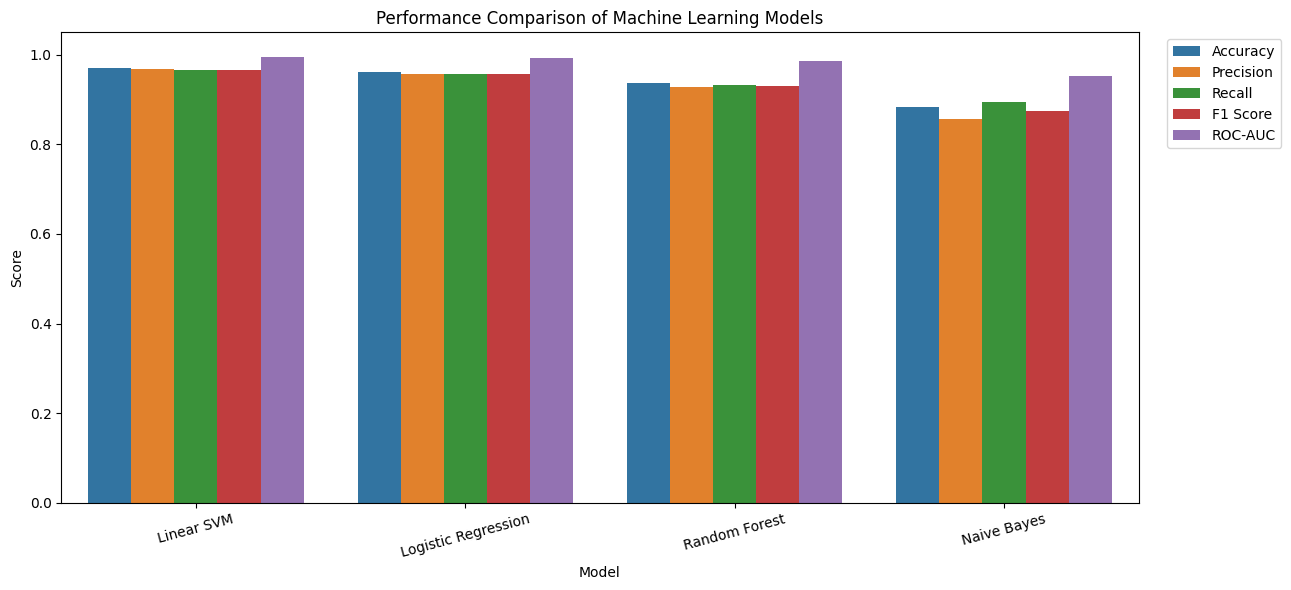

In [35]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

results_melted = results_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=results_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Performance Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

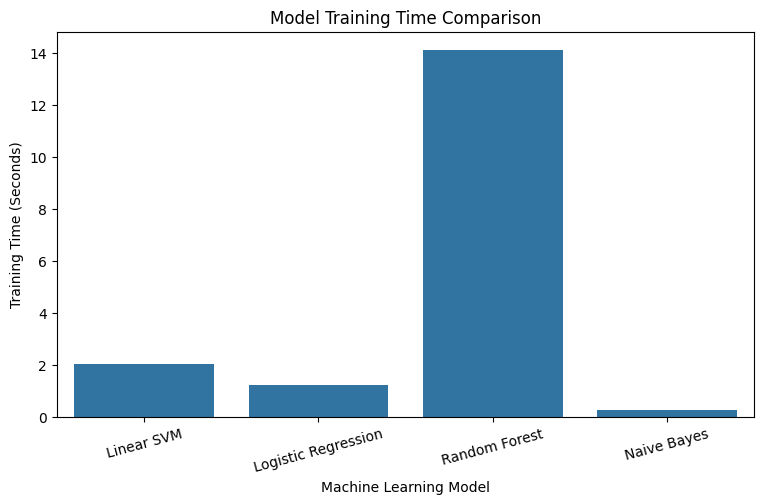

In [36]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Training Time (sec)"
)

plt.title("Model Training Time Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Training Time (Seconds)")
plt.xticks(rotation=15)

plt.show()

In [37]:
for model_name, model in trained_models.items():

    print("\n" + "=" * 70)
    print("MODEL:", model_name)
    print("=" * 70)

    print(
        classification_report(
            y_test,
            predictions[model_name],
            labels=[0, 1],
            target_names=["Fake News", "Real News"],
            zero_division=0
        )
    )


MODEL: Naive Bayes
              precision    recall  f1-score   support

   Fake News       0.91      0.87      0.89      6904
   Real News       0.86      0.90      0.87      5754

    accuracy                           0.88     12658
   macro avg       0.88      0.88      0.88     12658
weighted avg       0.88      0.88      0.88     12658


MODEL: Logistic Regression
              precision    recall  f1-score   support

   Fake News       0.96      0.96      0.96      6904
   Real News       0.96      0.96      0.96      5754

    accuracy                           0.96     12658
   macro avg       0.96      0.96      0.96     12658
weighted avg       0.96      0.96      0.96     12658


MODEL: Linear SVM
              precision    recall  f1-score   support

   Fake News       0.97      0.97      0.97      6904
   Real News       0.97      0.97      0.97      5754

    accuracy                           0.97     12658
   macro avg       0.97      0.97      0.97     12658
weighte

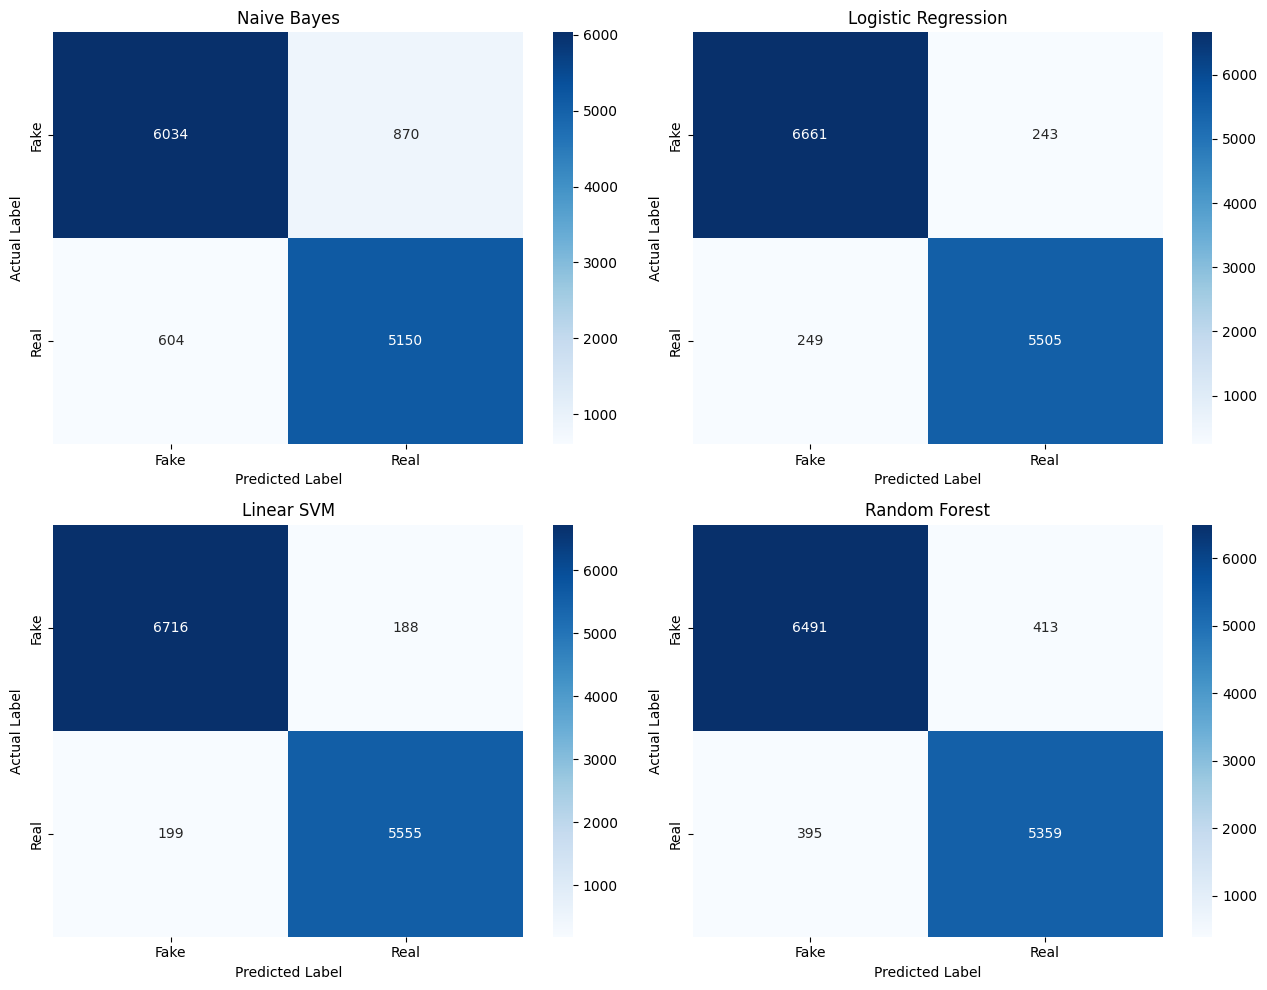

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

axes = axes.flatten()

for i, (model_name, y_pred) in enumerate(predictions.items()):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Fake", "Real"],
        yticklabels=["Fake", "Real"],
        ax=axes[i]
    )

    axes[i].set_title(f"{model_name}")
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

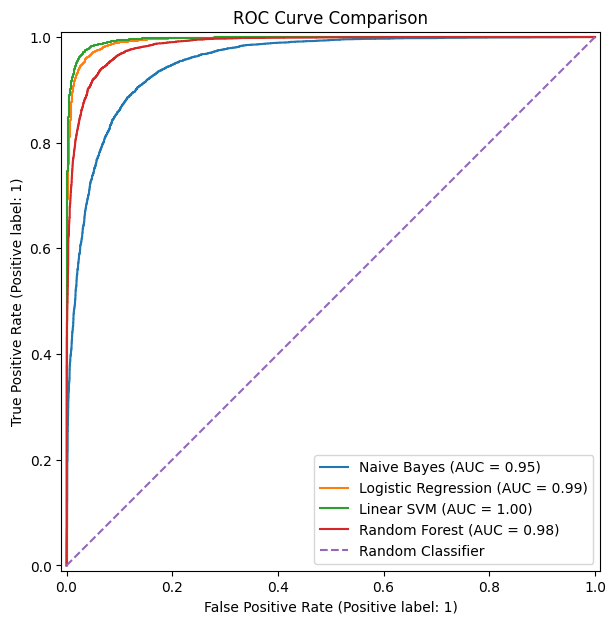

In [39]:
plt.figure(figsize=(9, 7))

for model_name, model in trained_models.items():

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test_tfidf)[:, 1]
    else:
        y_score = model.decision_function(X_test_tfidf)

    RocCurveDisplay.from_predictions(
        y_test,
        y_score,
        name=model_name,
        ax=plt.gca()
    )

plt.title("ROC Curve Comparison")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.legend()
plt.show()

In [40]:
# Recalculate evaluation metrics using macro averaging

results = []

for model_name, model in trained_models.items():

    y_pred = predictions[model_name]

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test_tfidf)[:, 1]
    else:
        y_score = model.decision_function(X_test_tfidf)

    results.append({
        "Model": model_name,

        "Accuracy": accuracy_score(y_test, y_pred),

        "Precision": precision_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),

        "Recall": recall_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),

        "F1 Score": f1_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(y_test, y_score),

        "Training Time (sec)": training_times[model_name]
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("\nBest Model:", best_model_name)
print("Best F1 Score:", round(
    results_df.iloc[0]["F1 Score"], 4
))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (sec)
0,Linear SVM,0.9694,0.9692,0.9691,0.9692,0.9958,2.0160
1,Logistic Regression,0.9611,0.9608,0.9608,0.9608,0.9935,1.2387
2,Random Forest,0.9362,0.9355,0.9358,0.9357,0.9849,14.1113
3,Naive Bayes,0.8836,0.8822,0.8845,0.8830,0.9528,0.2682



Best Model: Linear SVM
Best F1 Score: 0.9692


In [41]:
best_predictions = predictions[best_model_name]

error_df = pd.DataFrame({
    "News": X_test.values,
    "Actual": y_test.values,
    "Predicted": best_predictions
})

# Filter incorrect predictions
error_df = error_df[
    error_df["Actual"] != error_df["Predicted"]
].copy()

error_df["Actual"] = error_df["Actual"].map({
    0: "Fake",
    1: "Real"
})

error_df["Predicted"] = error_df["Predicted"].map({
    0: "Fake",
    1: "Real"
})

print("Total incorrect predictions:", len(error_df))

display(error_df.head(10))

Total incorrect predictions: 387


,News,Actual,Predicted
63,first take wall street bid goodbye june hike n...,Fake,Real
95,milo dear half america sears hate breitbart hi...,Fake,Real
98,wake america country upside folk work hard com...,Fake,Real
135,rajdeep sardesai column urt indian journalist ...,Real,Fake
154,congress planned parenthood investigation find...,Fake,Real
168,love woman except fat one ugly one feminist,Real,Fake
175,obama loretta lynch hold attorney general nomi...,Fake,Real
181,scientist told remain silent glyphosate cancer...,Real,Fake
198,watch reliable source explains trumpbart shape...,Real,Fake
227,photo show human right failure obama cuba poli...,Fake,Real


Error Category Distribution:
Error Type
Real classified as Fake    199
Fake classified as Real    188
Name: count, dtype: int64


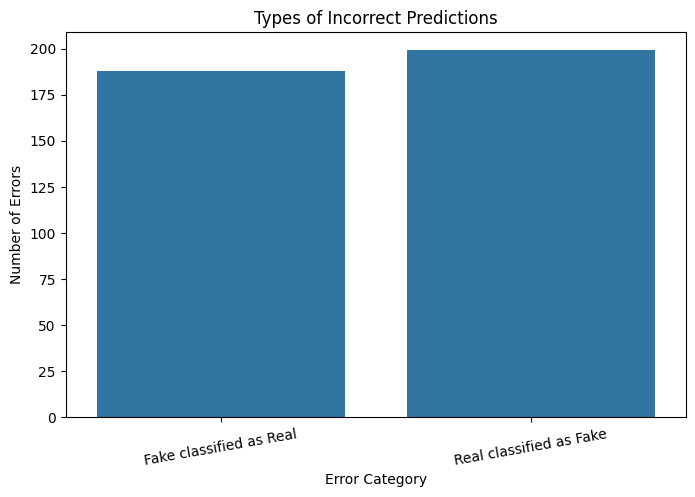

In [42]:
error_df["Error Type"] = error_df.apply(
    lambda row: (
        "Fake classified as Real"
        if row["Actual"] == "Fake"
        else "Real classified as Fake"
    ),
    axis=1
)

print("Error Category Distribution:")
print(error_df["Error Type"].value_counts())

plt.figure(figsize=(8, 5))

sns.countplot(
    data=error_df,
    x="Error Type"
)

plt.title("Types of Incorrect Predictions")
plt.xlabel("Error Category")
plt.ylabel("Number of Errors")
plt.xticks(rotation=10)

plt.show()

In [43]:
for _, row in error_df.head(5).iterrows():

    print("\nNews Article:")
    print(row["News"][:500])

    print("Actual:", row["Actual"])
    print("Predicted:", row["Predicted"])

    print("-" * 80)


News Article:
first take wall street bid goodbye june hike new york bye bye june rate hike billboard size headline wall street trading desk job creation machine hit wall may government said job created may way way way roughly new position wall street economist expecting worst month job creation since september janet yellen led federal reserve driving home message appropriate hike interest rate coming month perhaps early june job market economy continued perform well meet upbeat forecast may job report bad rea
Actual: Fake
Predicted: Real
--------------------------------------------------------------------------------

News Article:
milo dear half america sears hate breitbart hi folk eddie lampert ceo sears holding reliably informed everyone anyone conservative america read milo gracious enough lend column today send simple message sears failing brand fucking hate not first company think innovative customer relation strategy nordstrom took bold first leap openly shitting shopper dumpin

In [44]:
def predict_fake_news(news_text):

    if not isinstance(news_text, str) or not news_text.strip():
        return "Please enter a valid news article."

    # Apply the same preprocessing
    cleaned_text = preprocess_text(news_text)

    if not cleaned_text.strip():
        return "The article does not contain usable text."

    # Convert text into TF-IDF features
    text_vector = tfidf.transform([cleaned_text])

    # Predict using the best model
    prediction = best_model.predict(text_vector)[0]

    if prediction == 0:
        return "FAKE NEWS"

    return "REAL NEWS"

In [45]:
test_news = [
    """
    Scientists have announced a new discovery after conducting
    extensive research at a university laboratory.
    The research findings were published in a scientific journal.
    """,

    """
    A viral social media post claims that a secret government
    announcement will change the entire country tomorrow.
    However, no reliable evidence is provided for the claim.
    """,

    """
    The central bank released its latest economic report,
    providing information about inflation and financial growth.
    The report includes official economic statistics.
    """
]

for i, news in enumerate(test_news, 1):

    print(f"\nTest Article {i}")
    print("Prediction:", predict_fake_news(news))
    print("-" * 60)


Test Article 1
Prediction: REAL NEWS
------------------------------------------------------------

Test Article 2
Prediction: REAL NEWS
------------------------------------------------------------

Test Article 3
Prediction: REAL NEWS
------------------------------------------------------------


In [46]:
my_news = input("Enter a news article: ")

result = predict_fake_news(my_news)

print("\nPrediction Result:")
print(result)


Prediction Result:
REAL NEWS


In [47]:
os.makedirs("saved_model", exist_ok=True)

joblib.dump(
    best_model,
    "saved_model/best_fake_news_model.pkl"
)

joblib.dump(
    tfidf,
    "saved_model/tfidf_vectorizer.pkl"
)

joblib.dump(
    results_df,
    "saved_model/model_evaluation_results.pkl"
)

print("Model saved successfully!")
print("Vectorizer saved successfully!")
print("Evaluation results saved successfully!")

Model saved successfully!
Vectorizer saved successfully!
Evaluation results saved successfully!


In [48]:
loaded_model = joblib.load(
    "saved_model/best_fake_news_model.pkl"
)

loaded_vectorizer = joblib.load(
    "saved_model/tfidf_vectorizer.pkl"
)

sample_news = """
The government released its official annual economic report.
"""

cleaned = preprocess_text(sample_news)

vector = loaded_vectorizer.transform([cleaned])

prediction = loaded_model.predict(vector)[0]

print(
    "Loaded Model Prediction:",
    "Fake News" if prediction == 0 else "Real News"
)

Loaded Model Prediction: Real News


In [51]:
print("FINAL MODEL PERFORMANCE")
print("=" * 50)

print("Selected Model:", best_model_name)

print("\nEvaluation Metrics:")

print(
    classification_report(
        y_test,
        best_model.predict(X_test_tfidf),
        target_names=["Fake News", "Real News"],
        zero_division=0
    )
)

print("\nTotal Training Records:", len(X_train))
print("Total Testing Records:", len(X_test))
print("Total Incorrect Predictions:", len(error_df))

FINAL MODEL PERFORMANCE
Selected Model: Linear SVM

Evaluation Metrics:
              precision    recall  f1-score   support

   Fake News       0.97      0.97      0.97      6904
   Real News       0.97      0.97      0.97      5754

    accuracy                           0.97     12658
   macro avg       0.97      0.97      0.97     12658
weighted avg       0.97      0.97      0.97     12658


Total Training Records: 50631
Total Testing Records: 12658
Total Incorrect Predictions: 387


## 12. Conclusion

In this project, a Fake News Detection system was developed
using Natural Language Processing and Machine Learning.

The WELFake dataset was used to train and evaluate different
machine learning classification algorithms.

Text preprocessing techniques such as lowercasing, URL removal,
tokenization, stopword removal, and lemmatization were applied
to prepare the textual data.

TF-IDF was used for feature extraction to convert news articles
into numerical representations.

Four machine learning algorithms were implemented:
1. Multinomial Naive Bayes
2. Logistic Regression
3. Linear Support Vector Machine
4. Random Forest

The models were compared using accuracy, precision, recall,
F1-score, and ROC-AUC.

The best-performing model was selected based on its
macro F1-score.

The project demonstrates how NLP and machine learning
can be applied to text classification problems.

However, the system has limitations because it learns patterns
from the training dataset and cannot independently verify
whether a news article is factually correct.